(sec-4-1)=
# 4.1 Building Signals from Impulses

A sampled ECG is a sequence of numbers. One way to understand that sequence is to build it one sample at a time: place a marker at each sample position, give it the height of that sample, and add the markers together. The mathematical marker is called a *discrete impulse*.

I use this construction because it gives us a manageable way to describe a linear system. If we know how the system responds to one impulse, we can build its response to a more complicated input. We will work through the discrete case first, then take care with the different meaning of an impulse in continuous time.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)


def stem(ax, n, x, color=C[0], label=None, ms=5):
    """Draw a clean stem plot of the sequence x[n]."""
    ax.vlines(n, 0, x, color=color, lw=1.4)
    ax.plot(n, x, "o", color=color, ms=ms, label=label)
    ax.axhline(0, color="0.55", lw=0.8)

(sec-4-1-1)=
## 4.1.1 Signals as Sums of Shifted Impulses

Recall from Section 3.2 that the discrete-time unit impulse is

$$
\delta[n] = \begin{cases} 1, & n = 0, \\ 0, & n \neq 0. \end{cases}
$$

For the discrete impulse, only the sample at index zero is one. Shifting it to $\delta[n-k]$ moves that one to index $k$. Multiplying by $x[k]$ gives a sequence with just one nonzero sample, whose value is $x[k]$. Adding one such sequence for every index rebuilds the original signal.

The shifted impulse $\delta[n-k]$ is equal to one at the single index $n = k$ and zero everywhere else. Multiplying any signal $x[n]$ by $\delta[n-k]$ therefore wipes out every sample except the one at $n = k$:

(eq-4-1)=
\begin{equation*}
x[n]\,\delta[n-k] = x[k]\,\delta[n-k]. \tag{4.1}
\end{equation*}

The left side is a product of two sequences; the right side is the *number* $x[k]$ times a shifted impulse. They agree at $n = k$, where both equal $x[k]$, and at every other $n$, where both are zero.

Now sum equation [(4.1)](#eq-4-1) over all integers $k$. On the left, $x[n]$ does not depend on $k$ and comes out of the sum, leaving $\sum_k \delta[n-k]$. For any fixed $n$, exactly one term of that sum is nonzero (the one with $k = n$), so the sum equals one. We obtain

(eq-4-2)=
\begin{equation*}
x[n] = \sum_{k=-\infty}^{\infty} x[k]\,\delta[n-k]. \tag{4.2}
\end{equation*}

Equation [(4.2)](#eq-4-2) is the **sifting property** in discrete time. It looks almost too simple, but it says something useful: every discrete-time signal is a weighted sum of shifted impulses, and the weights are the sample values themselves. In the language of [Section 2.2](../ch02_math_toolkit/index.md), the shifted impulses form the standard basis of the signal space, and $x[k]$ is the coordinate of $x$ along the $k$-th basis vector.

**Example 4.1.1.** Write the four-sample signal $x[n] = \{1, 3, 2, -1\}$, starting at $n = 0$, as a sum of impulses.

Reading the samples off one by one, $x[0] = 1$, $x[1] = 3$, $x[2] = 2$ and $x[3] = -1$, so by equation [(4.2)](#eq-4-2)

$$
x[n] = 1\cdot\delta[n] + 3\,\delta[n-1] + 2\,\delta[n-2] - 1\cdot\delta[n-3].
$$

Each term is a single spike of the right height at the right place. The code below builds the four spikes separately and checks that their sum reproduces the signal.

In [2]:
def delta(n, k=0):
    """Unit impulse delta[n - k] evaluated on the integer array n."""
    return (n == k).astype(float)


n = np.arange(-2, 7)
samples = {0: 1.0, 1: 3.0, 2: 2.0, 3: -1.0}           # x[k] for k = 0..3
components = [x_k * delta(n, k) for k, x_k in samples.items()]
x = np.sum(components, axis=0)

print("n    :", n)
print("x[n] :", x)

n    : [-2 -1  0  1  2  3  4  5  6]
x[n] : [ 0.  0.  1.  3.  2. -1.  0.  0.  0.]


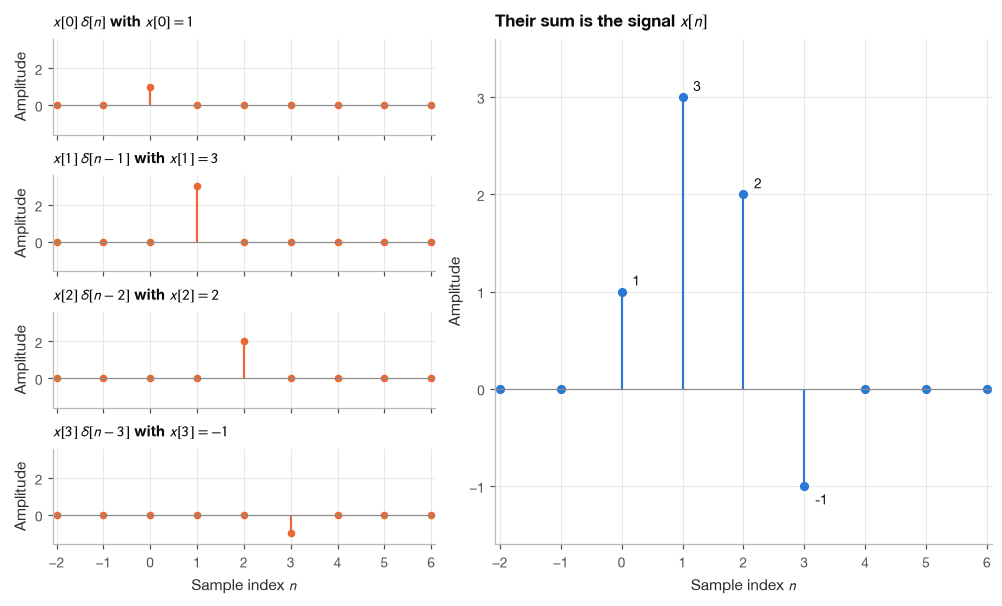

In [3]:
fig = plt.figure(figsize=(9, 5.4))
gs = fig.add_gridspec(4, 2, width_ratios=[1, 1.3])
for row, (k, x_k) in enumerate(samples.items()):
    ax = fig.add_subplot(gs[row, 0])
    stem(ax, n, components[row], color=C[1], ms=4)
    ax.set(ylim=(-1.6, 3.6), xticks=n, ylabel="Amplitude")
    shift = "n" if k == 0 else f"n-{k}"
    ax.set_title(f"$x[{k}]\\,\\delta[{shift}]$ with $x[{k}] = {x_k:g}$", fontsize=10)
    if row == 3:
        ax.set_xlabel("Sample index $n$")
    else:
        ax.tick_params(labelbottom=False)
ax = fig.add_subplot(gs[:, 1])
stem(ax, n, x, color=C[0])
for k, x_k in samples.items():
    ax.annotate(f"{x_k:g}", (k, x_k), textcoords="offset points",
                xytext=(7, 4 if x_k > 0 else -12), fontsize=9)
ax.set(ylim=(-1.6, 3.6), xticks=n, xlabel="Sample index $n$", ylabel="Amplitude",
       title="Their sum is the signal $x[n]$")
plt.show()

(sec-4-1-2)=
## 4.1.2 Continuous Time: The Staircase Approximation

A continuous-time signal has no "samples" to pick out, so we approach the same idea through a limit. Let $\Delta$ be a small time step and define a narrow rectangular pulse of width $\Delta$ and height $1/\Delta$:

$$
\delta_\Delta(t) = \begin{cases} 1/\Delta, & 0 \le t < \Delta, \\ 0, & \text{otherwise.} \end{cases}
$$

Its area is $\Delta \cdot (1/\Delta) = 1$ for every $\Delta$. The product $\Delta\,\delta_\Delta(t - k\Delta)$ is therefore a rectangle of unit *height* that occupies the interval $[k\Delta, (k+1)\Delta)$. If we scale that rectangle by the value of $x$ at its left edge and add up all such rectangles, we obtain a staircase that follows $x(t)$:

(eq-4-3)=
\begin{equation*}
\hat{x}(t) = \sum_{k=-\infty}^{\infty} x(k\Delta)\,\delta_\Delta(t - k\Delta)\,\Delta. \tag{4.3}
\end{equation*}

At any instant $t$, exactly one rectangle is "on", namely the one whose interval contains $t$, so $\hat{x}(t)$ equals the sample $x(k\Delta)$ taken at the start of that interval. As $\Delta$ shrinks, three things happen at once:

- the discrete grid $k\Delta$ fills in and becomes a continuous variable, which we call $\tau$;
- the width $\Delta$ becomes the infinitesimal $d\tau$, and the sum becomes an integral;
- the pulse $\delta_\Delta$ becomes ever taller and narrower with unit area, which is the Dirac delta $\delta$.

In the limit the staircase becomes the signal itself:

(eq-4-4)=
\begin{equation*}
x(t) = \int_{-\infty}^{\infty} x(\tau)\,\delta(t - \tau)\,d\tau. \tag{4.4}
\end{equation*}

This is the continuous-time sifting property. It can also be checked directly from the defining behavior of the delta. The factor $\delta(t-\tau)$ is zero for every $\tau \neq t$, so inside the integral $x(\tau)$ may be replaced by its value at $\tau = t$:

$$
\int_{-\infty}^{\infty} x(\tau)\,\delta(t - \tau)\,d\tau
= \int_{-\infty}^{\infty} x(t)\,\delta(t - \tau)\,d\tau
= x(t)\int_{-\infty}^{\infty} \delta(t - \tau)\,d\tau
= x(t)\cdot 1 .
$$

I like to keep the staircase picture in mind, because it is also how a computer sees a continuous signal: a sequence of values held over short intervals. The next cell approximates one smooth, synthetic ECG beat, built from five Gaussian bumps for the P wave, the Q, R and S deflections and the T wave, and measures how fast the staircase error shrinks as $\Delta$ decreases.

In [4]:
ECG_WAVES = [  # (name, amplitude in mV, center in s, width in s) of one synthetic beat
    ("P", 0.15, 0.20, 0.025), ("Q", -0.12, 0.37, 0.010), ("R", 1.20, 0.40, 0.012),
    ("S", -0.25, 0.43, 0.012), ("T", 0.30, 0.68, 0.050),
]


def ecg_beat(t):
    """Smooth synthetic ECG beat (mV) as a sum of Gaussian waves."""
    return sum(a * np.exp(-0.5 * ((t - c) / w) ** 2) for _, a, c, w in ECG_WAVES)


def staircase(x_func, t, width):
    """Staircase approximation of equation (5.3): hold x(k*width) over [k*width, (k+1)*width)."""
    return x_func(width * np.floor(t / width))


t_fine = np.linspace(0, 1, 40001)
for width in (0.04, 0.02, 0.01, 0.005, 0.0025):
    err = np.max(np.abs(ecg_beat(t_fine) - staircase(ecg_beat, t_fine, width)))
    print(f"Delta = {1000 * width:5.1f} ms   max |x - x_hat| = {err:.3f} mV")

Delta =  40.0 ms   max |x - x_hat| = 1.403 mV
Delta =  20.0 ms   max |x - x_hat| = 1.064 mV
Delta =  10.0 ms   max |x - x_hat| = 0.662 mV
Delta =   5.0 ms   max |x - x_hat| = 0.349 mV
Delta =   2.5 ms   max |x - x_hat| = 0.175 mV


Each halving of $\Delta$ roughly halves the largest error once $\Delta$ is small. That is the behavior we expect: within one step the staircase holds a constant value while the signal keeps moving, so the error is at most the steepest slope of the signal times $\Delta$. For an ECG the steepest slopes are on the flanks of the R wave, roughly 70 mV/s for this beat, so even a 5 ms step leaves an error of a few tenths of a millivolt. The P and T waves are far more forgiving. This is a first hint of why ECG sampling rates are set by the QRS complex, a theme of Chapter 6.

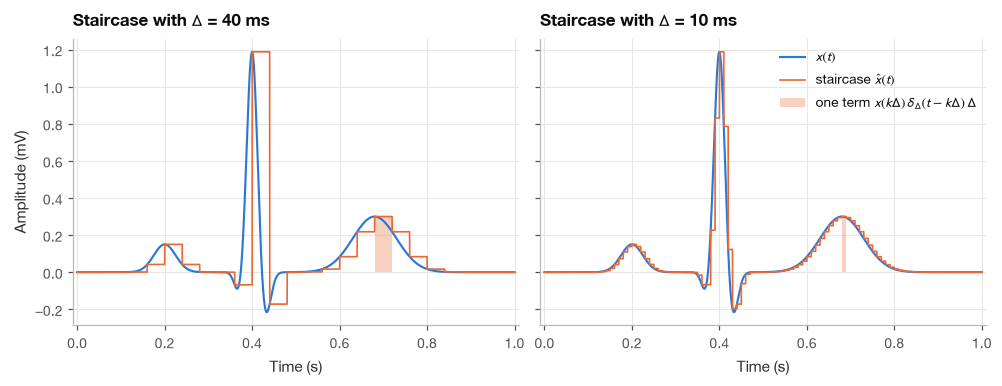

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, width in zip(axes, (0.04, 0.01)):
    ax.plot(t_fine, ecg_beat(t_fine), color=C[0], label="$x(t)$")
    ax.plot(t_fine, staircase(ecg_beat, t_fine, width), color=C[1], lw=1.1,
            label=r"staircase $\hat{x}(t)$")
    k = int(round(0.68 / width))
    ax.fill_between([k * width, (k + 1) * width], 0, ecg_beat(k * width),
                    color=C[1], alpha=0.3, lw=0, label=r"one term $x(k\Delta)\,\delta_\Delta(t-k\Delta)\,\Delta$")
    ax.set(xlabel="Time (s)", title=f"Staircase with $\\Delta$ = {1000 * width:.0f} ms")
axes[0].set_ylabel("Amplitude (mV)")
axes[1].legend(loc="upper right")
plt.show()

(sec-4-1-3)=
## 4.1.3 The Impulse Response

A system $T$ maps an input signal to an output signal. Its **impulse response** is simply the output produced when the input is a unit impulse applied at time zero, with the system initially at rest:

(eq-4-5)=
\begin{equation*}
h[n] = T\{\delta[n]\}, \qquad h(t) = T\{\delta(t)\}. \tag{4.5}
\end{equation*}

Physiology offers many approximations to this experiment. In the indicator-dilution method for measuring cardiac output, a small bolus of dye or cold saline is injected quickly into a vein, and its concentration is recorded downstream in an artery. The injection is short compared with the transit through the heart and lungs, so the concentration curve that follows is, to a good approximation, the impulse response of the circulation between the two sites, and the cardiac output is the injected amount divided by the area under that curve. A tap of the reflex hammer on the patellar tendon, a brief electrical pulse applied to a peripheral nerve, and a click delivered to the ear when recording auditory brainstem responses are all attempts to deliver an impulse and watch what comes back.

The definition [(4.5)](#eq-4-5) applies to any system, but the impulse response is only a *complete* description when the system is linear and time-invariant. The rest of this section explains why.

(sec-4-1-4)=
## 4.1.4 From Impulses to the Convolution Sum

Suppose $T$ is linear and time-invariant, with impulse response $h[n]$. We want its output $y[n] = T\{x[n]\}$ for an arbitrary input $x[n]$. The derivation takes three steps, and each step uses exactly one ingredient.

**Step 1: decompose the input.** By the sifting property [(4.2)](#eq-4-2),

$$
y[n] = T\{x[n]\} = T\Big\{\sum_{k} x[k]\,\delta[n-k]\Big\}.
$$

**Step 2: use linearity.** Inside the braces, the input is a weighted sum of the signals $\delta[n-k]$. From the system's point of view the weights $x[k]$ are fixed numbers; the variable is $n$. Linearity ([Section 3.2](../ch04_systems/02_linearity.ipynb)) says that the response to a weighted sum is the same weighted sum of the individual responses:

$$
y[n] = \sum_{k} x[k]\, T\{\delta[n-k]\}.
$$

**Step 3: use time invariance.** The signal $\delta[n-k]$ is the impulse delayed by $k$ samples. For a time-invariant system ([Section 4.3](../ch04_systems/index.md)), delaying the input delays the output by the same amount, so $T\{\delta[n-k]\} = h[n-k]$. Substituting gives the result:

(eq-4-6)=
\begin{equation*}
y[n] = \sum_{k=-\infty}^{\infty} x[k]\,h[n-k]. \tag{4.6}
\end{equation*}

This is the **convolution sum**, written compactly as $y = x * h$. It is the most important formula in this part of the book. The output of any LTI system is a superposition of copies of the impulse response: the input sample $x[k]$ launches a copy of $h$ that starts at time $k$ and is scaled by $x[k]$, and the output at time $n$ adds up the contributions of all those copies that are still active.

It is instructive to see what goes wrong without each property. Without time invariance, Step 3 fails: the response to an impulse at time $k$ would be some new sequence $h_k[n]$, and we would need a whole family of responses, one per $k$. Without linearity, Step 2 fails, and knowing the response to individual impulses tells us nothing about their sum.

The continuous-time argument follows the same three steps, starting from the staircase [(4.3)](#eq-4-3). Let $h_\Delta(t)$ denote the response to the narrow pulse $\delta_\Delta(t)$. Linearity and time invariance turn the staircase input into a staircase of responses,

$$
\hat{y}(t) = \sum_{k} x(k\Delta)\,h_\Delta(t - k\Delta)\,\Delta ,
$$

and as $\Delta \to 0$ the pulse response $h_\Delta$ approaches the impulse response $h$, $k\Delta$ becomes $\tau$, and the sum becomes an integral:

(eq-4-7)=
\begin{equation*}
y(t) = \int_{-\infty}^{\infty} x(\tau)\,h(t - \tau)\,d\tau. \tag{4.7}
\end{equation*}

This is the **convolution integral**, studied in detail in [Section 5.3](index.md).

### A numerical experiment: predicting a black box

We can test equation [(4.6)](#eq-4-6) without trusting any algebra. The function below is a "black box" whose internals we pretend not to know; in fact it is a second-order low-pass filter of the kind used to remove high-frequency noise. We measure its impulse response by feeding it a single impulse, then use equation [(4.6)](#eq-4-6) to *predict* its response to an arbitrary input, and finally compare the prediction with what the box actually produces.

In [6]:
b_box, a_box = signal.butter(2, 0.1)


def black_box(x):
    """An LTI system whose internals we treat as unknown."""
    return signal.lfilter(b_box, a_box, x)


def predict_by_superposition(x, h):
    """Equation (5.6): add one shifted, scaled copy of h for every input sample."""
    y = np.zeros(len(x) + len(h) - 1)
    for k, x_k in enumerate(x):
        y[k:k + len(h)] += x_k * h
    return y[:len(x)]


L = 200                                   # long enough for h to decay to ~0
h_measured = black_box(delta(np.arange(L)))
x_test = rng.normal(0, 1, 300)
y_true = black_box(x_test)
y_pred = predict_by_superposition(x_test, h_measured)
print(f"Largest |prediction - truth| for the LTI box: {np.max(np.abs(y_pred - y_true)):.2e}")

Largest |prediction - truth| for the LTI box: 5.55e-16


The prediction matches to within rounding error. Now repeat the experiment with a box that squares its input before filtering. Squaring is not linear, so the measured "impulse response" is no longer a complete description.

In [7]:
def nonlinear_box(x):
    """Square the input, then filter: not linear."""
    return signal.lfilter(b_box, a_box, x ** 2)


h_nl = nonlinear_box(delta(np.arange(L)))
y_nl_true = nonlinear_box(x_test)
y_nl_pred = predict_by_superposition(x_test, h_nl)
print(f"Largest |prediction - truth| for the nonlinear box: {np.max(np.abs(y_nl_pred - y_nl_true)):.2f}")
print(f"(output RMS for comparison: {np.sqrt(np.mean(y_nl_true ** 2)):.2f})")

Largest |prediction - truth| for the nonlinear box: 2.82
(output RMS for comparison: 0.99)


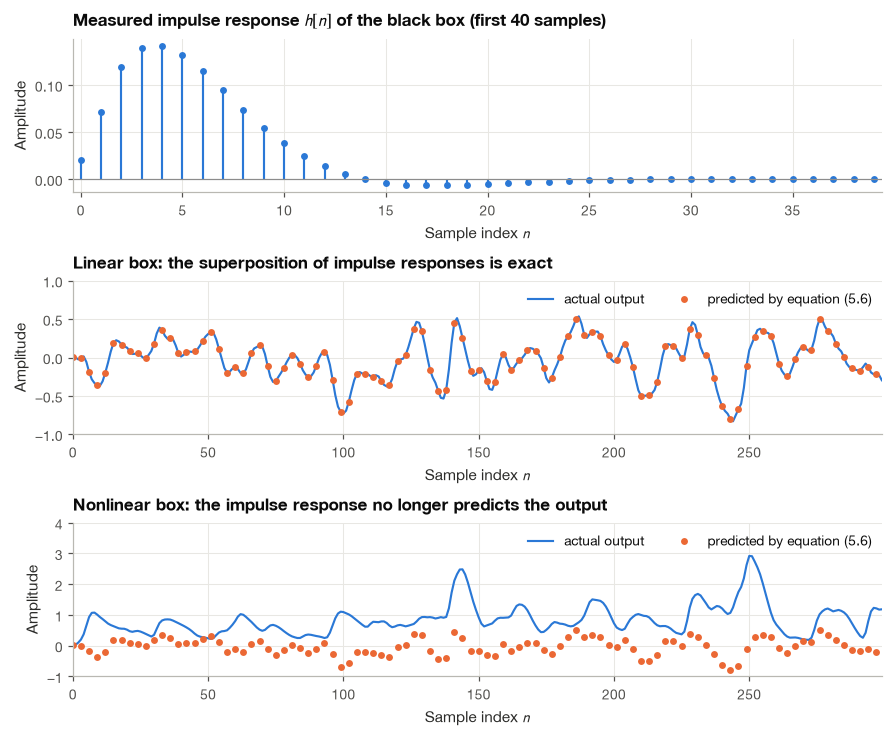

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(8, 6.6))
stem(axes[0], np.arange(40), h_measured[:40], color=C[0], ms=3.5)
axes[0].set(xlabel="Sample index $n$", ylabel="Amplitude",
            title="Measured impulse response $h[n]$ of the black box (first 40 samples)")

nn = np.arange(len(x_test))
axes[1].plot(nn, y_true, color=C[0], label="actual output")
axes[1].plot(nn[::3], y_pred[::3], "o", color=C[1], ms=3.5, label="predicted by equation (5.6)")
axes[1].set(xlabel="Sample index $n$", ylabel="Amplitude", xlim=(0, 299), ylim=(-1.0, 1.0),
            title="Linear box: the superposition of impulse responses is exact")
axes[1].legend(loc="upper right", ncol=2)

axes[2].plot(nn, y_nl_true, color=C[0], label="actual output")
axes[2].plot(nn[::3], y_nl_pred[::3], "o", color=C[1], ms=3.5, label="predicted by equation (5.6)")
axes[2].set(xlabel="Sample index $n$", ylabel="Amplitude", xlim=(0, 299), ylim=(-1.0, 4.0),
            title="Nonlinear box: the impulse response no longer predicts the output")
axes[2].legend(loc="upper right", ncol=2)
plt.show()

(sec-4-1-5)=
## 4.1.5 The Step Response

Impulses are awkward to produce in the laboratory. A true impulse needs a very large amplitude squeezed into a very short time, which tends to saturate amplifiers and, in physiological experiments, to stimulate tissue in ways we did not intend. A step, such as a switch closing or a calibration voltage turned on, is far easier to generate. Fortunately, the step response carries the same information as the impulse response.

Write the unit step as a sum of impulses. Since $u[k] = 1$ for $k \ge 0$ and $0$ otherwise, the sifting property [(4.2)](#eq-4-2) gives

(eq-4-8)=
\begin{equation*}
u[n] = \sum_{k=0}^{\infty} \delta[n-k]. \tag{4.8}
\end{equation*}

Feeding $x = u$ into the convolution sum [(4.6)](#eq-4-6), only the terms with $k \ge 0$ survive:

$$
s[n] = \sum_{k=-\infty}^{\infty} u[k]\,h[n-k] = \sum_{k=0}^{\infty} h[n-k].
$$

Substituting $m = n - k$: as $k$ runs from $0$ up to $\infty$, $m$ runs from $n$ down to $-\infty$, so

(eq-4-9)=
\begin{equation*}
s[n] = \sum_{m=-\infty}^{n} h[m]. \tag{4.9}
\end{equation*}

The **step response** is the running sum of the impulse response. Subtracting two consecutive values of [(4.9)](#eq-4-9) leaves only the newest term, which inverts the relationship:

(eq-4-10)=
\begin{equation*}
h[n] = s[n] - s[n-1]. \tag{4.10}
\end{equation*}

In continuous time the running sum becomes a running integral and the difference becomes a derivative:

(eq-4-11)=
\begin{equation*}
s(t) = \int_{-\infty}^{t} h(\tau)\,d\tau, \qquad h(t) = \frac{ds(t)}{dt}. \tag{4.11}
\end{equation*}

So we can measure the step response, which is easy, and differentiate it to obtain the impulse response, which is what the convolution sum needs. The catch is that differentiation amplifies measurement noise, a point we return to when discussing deconvolution in [Section 5.4](index.md).

(sec-4-1-6)=
## 4.1.6 Three Impulse Responses Worth Knowing

Three small systems appear again and again in ECG processing: the moving average smooths muscle noise, the first difference sharpens the QRS complex for beat detection, and the exponential smoother steadies the heart rate shown on a bedside monitor. We compute their impulse responses by feeding in $\delta[n]$ and their step responses with equation [(4.9)](#eq-4-9).

**The $M$-point moving average** replaces each sample by the mean of the current and $M - 1$ previous samples,

$$
y[n] = \frac{1}{M}\sum_{k=0}^{M-1} x[n-k].
$$

With $x = \delta$, the sum picks up the single nonzero input sample whenever $0 \le n \le M-1$, so $h[n] = 1/M$ on those $M$ samples and zero elsewhere: a short rectangle of total area one. Its step response climbs linearly, $s[n] = (n+1)/M$ for $0 \le n < M$, and stays at one afterwards. This is the simplest smoother; it averages away rapid fluctuations such as muscle noise on an ECG.

**The first difference**

$$
y[n] = x[n] - x[n-1]
$$

has impulse response $h[n] = \delta[n] - \delta[n-1]$: a positive spike followed by a negative one. Its step response is $s[n] = u[n] - u[n-1] = \delta[n]$, a single spike at the moment the step occurs, and nothing afterwards. The first difference responds only to change, which is why derivative stages appear at the start of QRS detectors such as the Pan–Tompkins algorithm of Section 19.1.

**The exponential smoother**

$$
y[n] = \alpha\,y[n-1] + (1-\alpha)\,x[n], \qquad 0 < \alpha < 1,
$$

computes each output from the previous output, so it is *recursive*. We find its impulse response by iterating from rest ($y[-1] = 0$) with $x = \delta$:

$$
\begin{aligned}
h[0] &= \alpha \cdot 0 + (1-\alpha)\cdot 1 = 1-\alpha, \\
h[1] &= \alpha\,(1-\alpha) + (1-\alpha)\cdot 0 = \alpha(1-\alpha), \\
h[2] &= \alpha \cdot \alpha(1-\alpha) = \alpha^2(1-\alpha),
\end{aligned}
$$

and the pattern continues, each new value being $\alpha$ times the previous one:

(eq-4-12)=
\begin{equation*}
h[n] = (1-\alpha)\,\alpha^{n}\,u[n]. \tag{4.12}
\end{equation*}

Unlike the moving average, this impulse response never quite reaches zero; it decays geometrically forever. Its step response follows from [(4.9)](#eq-4-9) and the finite geometric series $\sum_{m=0}^{n}\alpha^m = (1-\alpha^{n+1})/(1-\alpha)$:

$$
s[n] = \sum_{m=0}^{n} (1-\alpha)\,\alpha^m = (1-\alpha)\,\frac{1-\alpha^{n+1}}{1-\alpha} = 1 - \alpha^{n+1}, \qquad n \ge 0.
$$

[Section 5.5](index.md) studies this system in depth. The code implements all three systems directly from their defining equations, feeds them an impulse and a step, and checks the formulas.

In [9]:
def moving_average(x, M):
    """y[n] = (1/M) * sum_{k=0}^{M-1} x[n-k], with x[n] = 0 for n < 0."""
    y = np.zeros(len(x))
    for n_ in range(len(x)):
        y[n_] = np.sum(x[max(0, n_ - M + 1):n_ + 1]) / M
    return y


def first_difference(x):
    """y[n] = x[n] - x[n-1], with x[-1] = 0."""
    return x - np.concatenate([[0.0], x[:-1]])


def exponential_smoother(x, alpha):
    """y[n] = alpha*y[n-1] + (1 - alpha)*x[n], starting from rest."""
    y = np.zeros(len(x))
    prev = 0.0
    for n_, x_n in enumerate(x):
        prev = alpha * prev + (1 - alpha) * x_n
        y[n_] = prev
    return y


M, alpha = 5, 0.8
n = np.arange(-3, 18)
imp = delta(n)
step = (n >= 0).astype(float)
causal = n >= 0                        # the systems start at n = 0; earlier outputs are zero

systems = {
    f"Moving average, M = {M}": lambda x: moving_average(x, M),
    "First difference": first_difference,
    rf"Exponential smoother, $\alpha$ = {alpha}": lambda x: exponential_smoother(x, alpha),
}
responses = {}
for name, system in systems.items():
    h = np.zeros(n.size)
    s = np.zeros(n.size)
    h[causal] = system(imp[causal])
    s[causal] = system(step[causal])
    responses[name] = (h, s)

h_ma, s_ma = responses[f"Moving average, M = {M}"]
h_es, s_es = responses[rf"Exponential smoother, $\alpha$ = {alpha}"]
print("Moving average h matches 1/M rectangle   :", np.allclose(h_ma, np.where((n >= 0) & (n < M), 1 / M, 0)))
print("Smoother h matches (1-a) a^n u[n]  (5.12):", np.allclose(h_es, (1 - alpha) * alpha ** n * causal))
print("Smoother s matches 1 - a^(n+1)           :", np.allclose(s_es, (1 - alpha ** (n + 1)) * causal))
print("Running sum of h equals s, all systems   :",
      all(np.allclose(np.cumsum(h), s) for h, s in responses.values()))

Moving average h matches 1/M rectangle   : True
Smoother h matches (1-a) a^n u[n]  (5.12): True
Smoother s matches 1 - a^(n+1)           : True
Running sum of h equals s, all systems   : True


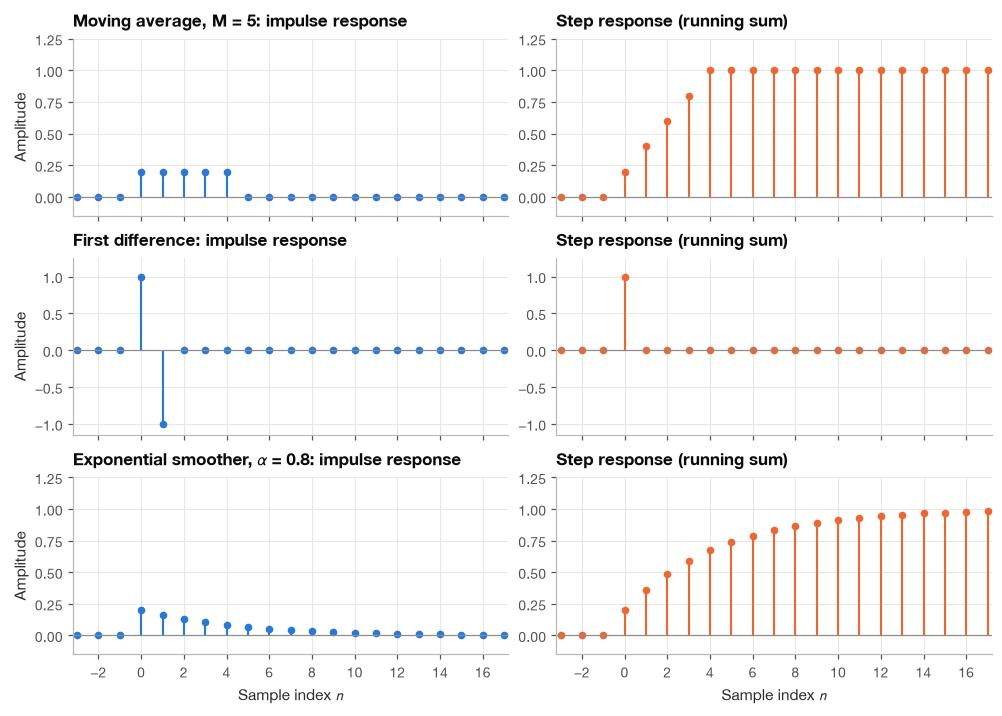

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(9, 6.4), sharex=True)
for row, (name, (h, s)) in enumerate(responses.items()):
    stem(axes[row, 0], n, h, color=C[0], ms=4)
    stem(axes[row, 1], n, s, color=C[1], ms=4)
    axes[row, 0].set(ylabel="Amplitude", title=f"{name}: impulse response")
    axes[row, 1].set(title="Step response (running sum)")
    lo = min(h.min(), 0) - 0.15
    for ax in axes[row]:
        ax.set_ylim(lo, 1.25)
for ax in axes[-1]:
    ax.set_xlabel("Sample index $n$")
    ax.set_xticks(np.arange(-2, 18, 2))
plt.show()

The figure makes the different personalities of the three systems visible. The moving average reaches its final value after exactly $M$ samples and then stops changing. The first difference ignores the constant part of the step completely. The exponential smoother approaches its final value gradually and never quite arrives, which is the signature of a system with feedback.

(sec-4-1-7)=
## 4.1.7 Measuring Responses in Practice: AC Coupling in an ECG Amplifier

We now return to the calibration pulse from the introduction. Skin electrodes develop DC offset potentials of tens of millivolts, far larger than the 1 mV ECG, and these offsets drift slowly as the electrode gel settles. If they reached the high-gain stages of the amplifier, they would saturate it. ECG front ends therefore block DC with a high-pass stage, called **AC coupling** (Section 11.2). In its simplest form it is a series capacitor followed by a resistor to ground, a first-order RC high-pass circuit with time constant $\tau = RC$.

I find this example worth working through slowly, because it shows the whole chain of ideas of this section on one real problem: a step response measured on paper becomes an impulse response, and the impulse response, through the convolution sum, predicts what the amplifier does to every heartbeat. We proceed in five steps.

### Step 1: Describe the coupling stage by its step response

When a unit step is applied, the capacitor initially passes the jump unchanged, so the output jumps to one. The capacitor then charges through the resistor, and the voltage across it rises as $1 - e^{-t/\tau}$; the output is the input minus the capacitor voltage. Hence

$$
s(t) = 1 - \left(1 - e^{-t/\tau}\right) = e^{-t/\tau}\,u(t).
$$

Equation [(4.11)](#eq-4-11) turns this into the impulse response. Differentiating the jump at $t = 0$ produces a unit impulse, and differentiating the decaying exponential produces a negative tail:

(eq-4-13)=
\begin{equation*}
h(t) = \frac{ds}{dt} = \delta(t) - \frac{1}{\tau}\,e^{-t/\tau}\,u(t). \tag{4.13}
\end{equation*}

The impulse passes the input straight through; the negative tail subtracts a slowly fading memory of the recent past. That tail is what removes the DC offset, and it is also what distorts the ECG. Diagnostic electrocardiographs use a cutoff of $f_c = 1/(2\pi\tau) = 0.05$ Hz, which gives $\tau = 3.18$ s. Bedside monitors often use 0.5 Hz ($\tau = 0.32$ s) to recover more quickly from movement artifacts.

### Step 2: Predict the calibration pulse

The standard calibration pulse is a 1 mV rectangle lasting about 0.2 s, that is, $x(t) = u(t) - u(t - 0.2)$ in millivolts. Because the system is linear and time-invariant, the response is the step response minus a delayed step response:

$$
y(t) = s(t) - s(t - 0.2) = e^{-t/\tau}u(t) - e^{-(t - 0.2)/\tau}\,u(t - 0.2).
$$

Just before the pulse ends, the output has decayed to $e^{-0.2/\tau}$. When the input drops by 1 mV, the output drops by the same amount and lands at $e^{-0.2/\tau} - 1$, below the baseline, after which it recovers with the same time constant.

In [11]:
fs = 360                                         # MIT-BIH sampling rate (Hz)
t = np.arange(-0.2, 1.4, 1 / fs)
width = 0.2                                      # calibration pulse width (s)


def rc_highpass_step(t, tau):
    """Step response of a first-order RC high-pass: exp(-t/tau) u(t)."""
    return np.where(t >= 0, np.exp(-np.clip(t, 0, None) / tau), 0.0)


cal_in = ((t >= 0) & (t < width)).astype(float)
cal_out = {}
for fc in (0.05, 0.5):
    tau = 1 / (2 * np.pi * fc)
    cal_out[fc] = rc_highpass_step(t, tau) - rc_highpass_step(t - width, tau)
    top = np.exp(-width / tau)
    print(f"fc = {fc:4.2f} Hz  tau = {tau:5.2f} s   top sags to {top:.3f} mV,"
          f"   undershoot {top - 1:+.3f} mV")

fc = 0.05 Hz  tau =  3.18 s   top sags to 0.939 mV,   undershoot -0.061 mV
fc = 0.50 Hz  tau =  0.32 s   top sags to 0.533 mV,   undershoot -0.467 mV


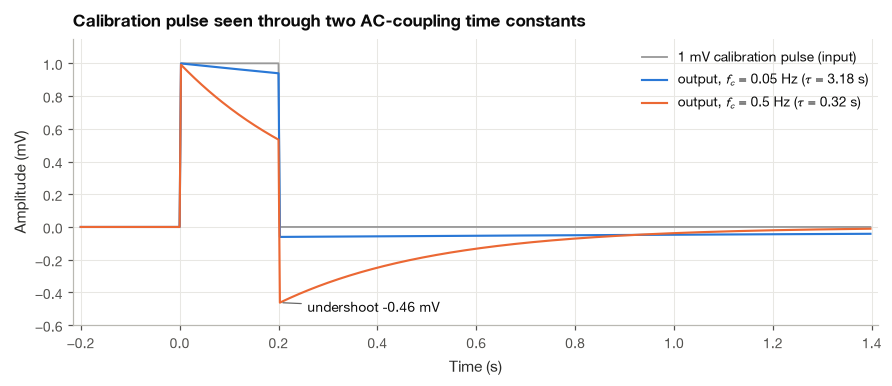

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(t, cal_in, color="0.6", lw=1.2, label="1 mV calibration pulse (input)")
ax.plot(t, cal_out[0.05], color=C[0], label=r"output, $f_c$ = 0.05 Hz ($\tau$ = 3.18 s)")
ax.plot(t, cal_out[0.5], color=C[1], label=r"output, $f_c$ = 0.5 Hz ($\tau$ = 0.32 s)")
i_end = np.searchsorted(t, width)
ax.annotate(f"undershoot {cal_out[0.5][i_end]:+.2f} mV", (t[i_end], cal_out[0.5][i_end]),
            textcoords="offset points", xytext=(18, -6), fontsize=9,
            arrowprops=dict(arrowstyle="-", color="0.4", lw=0.8))
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)", ylim=(-0.6, 1.15),
       title="Calibration pulse seen through two AC-coupling time constants")
ax.legend(loc="upper right")
plt.show()

With the diagnostic setting the top of the pulse sags by only 6 %, and the undershoot of 0.06 mV is barely visible. With the monitoring setting the top loses almost half its height and the trace dips nearly 0.5 mV below baseline. Read in reverse, this is a measurement procedure: the time constant follows from the sag of the top, $\tau = -0.2 / \ln(\text{top}/1\ \text{mV})$, which is how the low-frequency behavior of an electrocardiograph can be checked from its own printout.

### Step 3: Convert the step response into a discrete impulse response

To apply the coupling to a digital recording, we need its impulse response in discrete time. Sampling the step response gives $s[n] = e^{-n T_s/\tau}$ for $n \ge 0$, and equation [(4.10)](#eq-4-10) converts it into an impulse response:

$$
h[0] = s[0] - s[-1] = 1, \qquad h[n] = e^{-nT_s/\tau} - e^{-(n-1)T_s/\tau}, \quad n \ge 1.
$$

The values for $n \ge 1$ are small and negative, the discrete version of the tail in [(4.13)](#eq-4-13). I truncate $h$ after $8\tau$, where the tail has fallen below $e^{-8} \approx 3\times 10^{-4}$ of its initial value; a longer impulse response would change nothing visible and would only cost computation.

In [13]:
def ac_coupling_ir(tau, fs, n_tau=8):
    """Discrete impulse response of an RC high-pass, from its sampled step response via (5.10)."""
    s = np.exp(-np.arange(int(n_tau * tau * fs)) / (tau * fs))
    return np.diff(np.concatenate([[0.0], s]))


h_cpl = {fc: ac_coupling_ir(1 / (2 * np.pi * fc), fs) for fc in (0.05, 0.5)}
for fc, h in h_cpl.items():
    print(f"fc = {fc:4.2f} Hz: {h.size:5d} taps, h[0] = {h[0]:.0f}, h[1] = {h[1]:.2e}, sum(h) = {h.sum():.1e}")

fc = 0.05 Hz:  9167 taps, h[0] = 1, h[1] = -8.72e-04, sum(h) = 3.4e-04
fc = 0.50 Hz:   916 taps, h[0] = 1, h[1] = -8.69e-03, sum(h) = 3.4e-04


The taps sum almost to zero, which is how the filter removes DC: a constant input multiplies the sum of the taps, as we will prove in [Section 5.4](index.md).

### Step 4: Load a real ECG and pass it through both couplings

I chose record 119 of the MIT-BIH Arrhythmia Database {cite:p}`moody2001,goldberger2000` because its normal beats have a tall, mostly positive QRS complex in lead MLII, which is exactly the shape that suffers most from AC coupling. The record was acquired with a much lower cutoff, so we can treat it as the "true" ECG and ask what each coupling would have done to it. We read the first five minutes and compute each output with the convolution sum [(4.6)](#eq-4-6). NumPy's `np.convolve` evaluates that sum efficiently; [Section 4.2](02_convolution_sum.ipynb) shows how it works inside.

In [14]:
rec = wfdb.rdrecord("../data/mitdb/119", sampto=300 * fs)
ecg = rec.p_signal[:, 0]                         # lead MLII (mV)
ann = wfdb.rdann("../data/mitdb/119", "atr", sampto=300 * fs)
coupled = {fc: np.convolve(ecg, h)[:ecg.size] for fc, h in h_cpl.items()}
print(f"Loaded {ecg.size / fs:.0f} s of lead {rec.sig_name[0]} at {rec.fs} Hz, {ann.sample.size} annotations")

Loaded 300 s of lead MLII at 360 Hz, 349 annotations


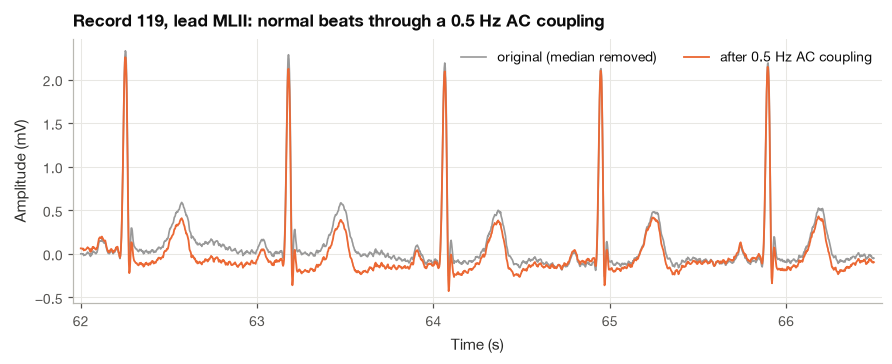

In [15]:
t0, t1 = 62.0, 66.5                              # a stretch of normal beats only
seg = slice(int(t0 * fs), int(t1 * fs))
tt = np.arange(seg.start, seg.stop) / fs
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(tt, ecg[seg] - np.median(ecg[seg]), color="0.6", lw=1.1, label="original (median removed)")
ax.plot(tt, coupled[0.5][seg], color=C[1], lw=1.2, label="after 0.5 Hz AC coupling")
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)",
       title="Record 119, lead MLII: normal beats through a 0.5 Hz AC coupling")
ax.legend(loc="upper right", ncol=2)
plt.show()

Even by eye, the coupled trace sits lower than the original right after each QRS complex and creeps back up during the T wave.

### Step 5: Average the normal beats and measure the ST shift

Single beats are noisy, so we average many of them. We keep only normal beats whose neighbors are also normal (so that the large ventricular ectopic beats in this record do not leave their own undershoot behind), skip the first 30 s while the long filter settles, and measure the ST level as the mean amplitude 80 to 120 ms after the R peak, relative to the PR baseline 100 to 60 ms before it.

In [16]:
symbols = np.array(ann.symbol)
is_beat = np.isin(symbols, list("NVAFSQ"))
beat_idx, beat_sym = ann.sample[is_beat], symbols[is_beat]
keep = (beat_sym[1:-1] == "N") & (beat_sym[:-2] == "N") & (beat_sym[2:] == "N")
r_peaks = beat_idx[1:-1][keep]
r_peaks = r_peaks[r_peaks > 30 * fs]

offsets = np.arange(-int(0.25 * fs), int(0.5 * fs))
t_beat = offsets / fs


def average_beat(x, r_peaks):
    """Ensemble average of x around each R peak, with the PR baseline subtracted."""
    avg = np.array([x[r + offsets] for r in r_peaks]).mean(axis=0)
    return avg - avg[(t_beat >= -0.10) & (t_beat < -0.06)].mean()


st_window = (t_beat >= 0.08) & (t_beat < 0.12)
averages = {"original": average_beat(ecg, r_peaks)}
averages.update({f"{fc} Hz coupling": average_beat(coupled[fc], r_peaks) for fc in (0.05, 0.5)})
st_orig = averages["original"][st_window].mean()
table = pd.DataFrame([{"signal": name, "ST level (mV)": avg[st_window].mean(),
                       "shift (mV)": avg[st_window].mean() - st_orig} for name, avg in averages.items()])
print(f"Normal beats averaged: {len(r_peaks)}")
print(table.round(3).to_string(index=False))

Normal beats averaged: 108
          signal  ST level (mV)  shift (mV)
        original         -0.016       0.000
0.05 Hz coupling         -0.025      -0.009
 0.5 Hz coupling         -0.086      -0.070


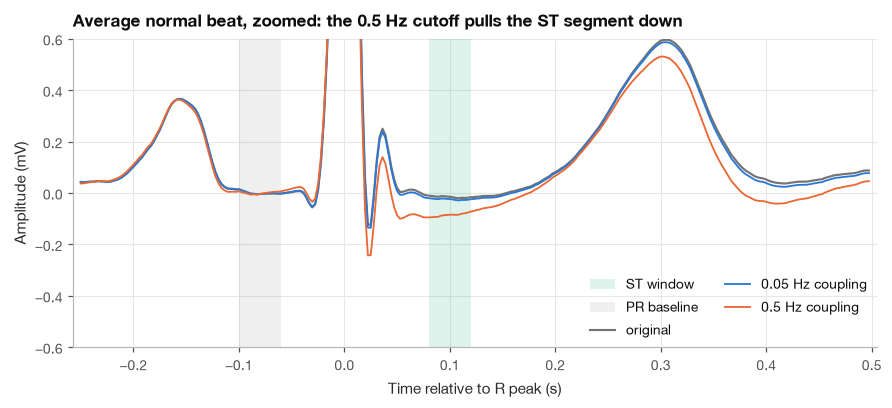

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axvspan(0.08, 0.12, color=C[2], alpha=0.15, lw=0, label="ST window")
ax.axvspan(-0.10, -0.06, color="0.5", alpha=0.12, lw=0, label="PR baseline")
ax.plot(t_beat, averages["original"], color="0.45", lw=1.4, label="original")
ax.plot(t_beat, averages["0.05 Hz coupling"], color=C[0], lw=1.2, label="0.05 Hz coupling")
ax.plot(t_beat, averages["0.5 Hz coupling"], color=C[1], lw=1.2, label="0.5 Hz coupling")
ax.set(xlabel="Time relative to R peak (s)", ylabel="Amplitude (mV)", ylim=(-0.6, 0.6),
       title="Average normal beat, zoomed: the 0.5 Hz cutoff pulls the ST segment down")
ax.legend(loc="lower right", ncol=2)
plt.show()

The 0.05 Hz coupling moves the ST level by about 0.01 mV, which no one would notice. The 0.5 Hz coupling pushes it down by about 0.07 mV. That is most of the 0.1 mV (1 mm) of ST depression commonly used as a threshold for myocardial ischemia, produced entirely by the amplifier; a patient whose true ST segment is depressed by only 0.03 mV would cross the threshold on such a monitor.

The convolution sum tells us where this artifact comes from. Each sample of the tall QRS launches a copy of $h$, and every copy carries the negative tail $-(1/\tau)e^{-t/\tau}$. A few tens of milliseconds after the QRS those tails have barely begun to decay, so together they contribute roughly $-(\text{QRS area})/\tau$. We can check the order of magnitude directly.

In [18]:
qrs_area = np.sum(averages["original"][(t_beat >= -0.06) & (t_beat < 0.06)]) / fs   # mV*s
for fc in (0.05, 0.5):
    tau = 1 / (2 * np.pi * fc)
    print(f"fc = {fc:4.2f} Hz: -(QRS area)/tau = {-qrs_area / tau:+.3f} mV")
print(f"QRS area over +-60 ms: {1000 * qrs_area:.0f} mV*ms")

fc = 0.05 Hz: -(QRS area)/tau = -0.018 mV
fc = 0.50 Hz: -(QRS area)/tau = -0.179 mV
QRS area over +-60 ms: 57 mV*ms


The estimate overshoots the measured 0.07 mV because the tails keep decaying during the 80 to 120 ms before the ST window and because the PR reference is itself pulled down slightly by the previous beat, but it gets the sign and the order of magnitude right, and it explains why the 0.05 Hz setting, with a ten times longer $\tau$, is harmless.

```{note}
Guidelines for diagnostic electrocardiography keep the low-frequency cutoff at 0.05 Hz precisely to avoid this kind of ST distortion, allowing higher cutoffs (up to about 0.67 Hz) only for filters that introduce no phase distortion {cite:p}`kligfield2007`. The zero-phase filters that make this possible are described in Section 15.3, and high-pass filtering of the ECG is treated step by step in Section 18.2.
```

## Summary

Any discrete-time signal is a weighted sum of shifted impulses, $x[n] = \sum_k x[k]\,\delta[n-k]$, and any continuous-time signal is the limit of a staircase of narrow unit-area pulses, which gives the sifting property $x(t) = \int x(\tau)\,\delta(t-\tau)\,d\tau$. The impulse response $h$ is the output of a system at rest when the input is a unit impulse. For an LTI system, decomposing the input into impulses, applying linearity and then time invariance leads directly to the convolution sum $y[n] = \sum_k x[k]\,h[n-k]$ and the convolution integral $y(t) = \int x(\tau)\,h(t-\tau)\,d\tau$. We confirmed numerically that a measured impulse response predicts a linear system's output exactly and fails for a nonlinear one.

The step response is the running sum (or running integral) of the impulse response, so the two carry the same information, and steps are easier to apply in practice. The moving average, the first difference and the exponential smoother have a rectangular, a two-spike and a geometrically decaying impulse response, respectively. Finally, modeling an ECG amplifier's AC coupling through its step response showed how the negative tail of a high-pass impulse response depresses the ST segment, by about 0.07 mV for a 0.5 Hz cutoff on record 119. In the next section I turn the convolution sum into a computational tool and look at it from several angles.

## Exercises

1. Write $x[n] = 2\delta[n+1] - \delta[n] + 0.5\,\delta[n-2]$ as a list of samples with their indices. Then express $x[n] = (0.5)^n$ for $0 \le n \le 3$ (zero elsewhere) as a sum of four scaled, shifted impulses.
2. Show that for a continuous-time signal the staircase error satisfies $|x(t) - \hat{x}(t)| \le \Delta \max_t |x'(t)|$. Compute $\max_t |x'(t)|$ for the synthetic ECG beat of [Section 4.1.2](#sec-4-1-2) numerically and compare the bound with the errors printed in the text. Which wave sets the bound?
3. A system has impulse response $h[n] = \delta[n] + 0.5\,\delta[n-1] + 0.25\,\delta[n-2]$. Use equation [(4.9)](#eq-4-9) to compute its step response by hand for $n = -1, 0, 1, 2, 3$. Verify your answer by implementing the system as a function and feeding it a step.
4. The black box of [Section 4.1.4](#sec-4-1-4) was linear and time-invariant. Construct a box that is linear but *time-varying* (for example, $y[n] = n\,x[n]$ followed by the same low-pass filter). Measure its "impulse response" with an impulse at $n = 0$, try to predict its output to a random input with equation [(4.6)](#eq-4-6), and explain the failure in terms of Step 3 of the derivation.
5. Simulate a recorded calibration pulse for an amplifier with $f_c = 0.05$ Hz by adding white noise with a standard deviation of 5 µV to the ideal response, sampled at 500 Hz. Estimate $\tau$ by fitting a straight line to $\ln y(t)$ over the top of the pulse. How accurate is the estimate, and how would you improve it?
6. Repeat the ST measurement of [Section 4.1.7](#sec-4-1-7) for the ventricular ectopic beats (symbol `V`) of record 119. Why is the shift so much larger for these beats? Relate your answer to the QRS area and to the estimate $-(\text{QRS area})/\tau$.

## Further Reading

The derivation of the convolution sum from the sifting property follows the classic presentation in {cite:t}`oppenheim1997` (Chapter 2), which also treats the continuous-time staircase argument in detail; {cite:t}`lathi2018` gives a gentler version with many worked examples. The design of ECG input stages, electrode offset potentials and AC coupling is covered in {cite:t}`webster2010`, and the recommendations on low-frequency cutoffs for diagnostic ECG are in {cite:t}`kligfield2007`. The MIT-BIH Arrhythmia Database is described by {cite:t}`moody2001` and distributed through PhysioNet {cite:p}`goldberger2000`.